# Unsupervised Learning and K-Means Clustering

##  What is Unsupervised Learning?

**Unsupervised Learning** is a type of machine learning where the model is trained on **unlabeled data**. The goal is to **find hidden patterns or structures** in the data without any predefined output labels.

Unlike supervised learning (where we predict a known target), unsupervised learning explores the data to group or reduce it.

### Common Tasks:
- **Clustering:** Group similar data points (e.g., K-Means)
- **Dimensionality Reduction:** Reduce the number of features (e.g., PCA)

---

## Real-Life Applications of Unsupervised Learning

| Application | Description |
|-------------|-------------|
| Customer Segmentation | Group customers by behavior or purchase patterns |
| Anomaly Detection | Detect fraud or outliers in transactions or systems |
| Topic Modeling | Automatically organize documents or articles into topics |
| Image Compression | Reduce file size using clustering of pixel patterns |

---


##  K-Means Clustering – Step by Step

**K-Means** is a clustering algorithm used to group data into `K` clusters based on similarity.

### Step-by-Step:

1. **Choose the number of clusters (K)**.
2. **Randomly initialize K centroids**.
3. **Assign each data point to the nearest centroid**.
4. **Update centroids** as the mean of all points in that cluster.
5. **Repeat steps 3–4** until centroids don’t change significantly or a max number of iterations is reached.

---

# [Visualizing Kmeans](https://www.naftaliharris.com/blog/visualizing-k-means-clustering/)

### Will we find the optimal configuration?

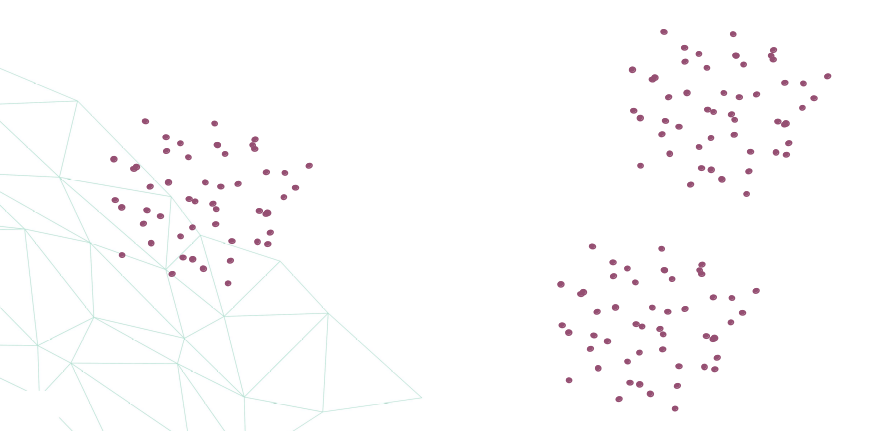

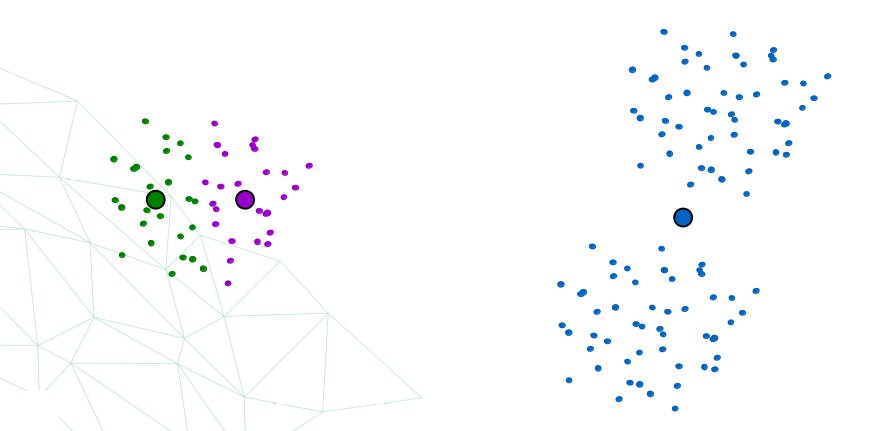

> Idea 1: Be careful about where you start.

> Idea 2: Do many runs of k-means, each from a different random start configuration

> Neat trick:
- Place first center on top of randomly chosen datapoint.

- Place second center on datapoint that’s as far away as possible from first center

- Place j’th center on datapoint that’s as far away as possible from the closest of Centers 1 through j-1


## ⚖️ Strengths and Weaknesses of K-Means Clustering

### ✅ Strengths

- **Simple and Fast:** K-Means is easy to implement and computationally efficient, especially on large datasets.
- **Scales Well:** Performs well with a large number of features and samples.
- **Interpretable Results:** The clusters are easy to understand and visualize (especially in 2D or 3D).
- **General Purpose:** Useful in many domains like marketing, biology, image compression, etc.

---

### ❌ Weaknesses

- **Requires K in Advance:** You must choose the number of clusters `K` before running the algorithm.
- **Sensitive to Initialization:** Random choice of initial centroids can lead to different results (can use `k-means++` to mitigate).
- **Assumes Spherical Clusters:** Works best when clusters are roughly circular and similar in size.
- **Not Robust to Outliers:** Outliers can skew the centroids significantly.
- **Fails with Non-Linear Structures:** Cannot capture complex patterns like concentric circles or spirals.

---


**Sensitive to Initialization**


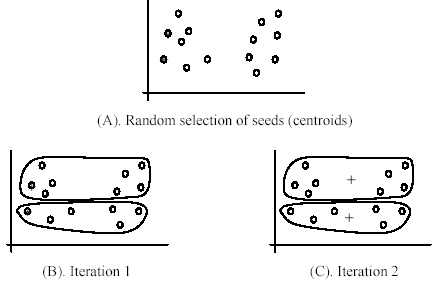


**Not Robust to Outliers**

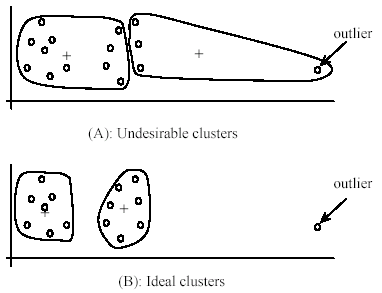


### Tip:
To improve K-Means performance:
- Use **feature scaling** (e.g., StandardScaler).
- Try **multiple runs with different seeds**.
- Use **Elbow method** or **Silhouette score** to choose `K`.
- Consider **alternative clustering** methods (e.g., DBSCAN or Gaussian Mixture Models) if K-Means performs poorly.


In [1]:
import warnings
warnings.filterwarnings('ignore')


In [2]:
# import the libraries
import numpy as np
import pandas as pd 
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objs as go
from plotly import tools
from plotly.subplots import make_subplots
import plotly.offline as py

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")

print("Path to dataset files:", path)

Path to dataset files: /home/aya/.cache/kagglehub/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/versions/1


In [4]:
!ls $path

Mall_Customers.csv


In [5]:
import os 
file_name = os.listdir(path)[0]
full_path = os.path.join(path,file_name)

df = pd.read_csv(full_path)

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [7]:
# creating a two dimentional matrix 
x = df.iloc[:,[3,4]].values

# 🔍 KMeans Parameters Explained

This section provides a detailed explanation of the parameters used in `sklearn.cluster.KMeans`.

---

### ✅ `n_clusters` (int, default=8)
- Number of clusters to form.
- Must be an integer ≥ 1.

📌 *Example:*  
`n_clusters=3` → Try to form 3 clusters from the data.

---

### ✅ `init` (str or array, default='k-means++')
- Method for initializing the centroids.

### Options:
- `'k-means++'` *(recommended)*: Smart initialization to speed up convergence.
    #### How it works:
    1. Choose the **first centroid** randomly from the data points.
    2. For each remaining data point, compute the distance to the **nearest already chosen centroid**.
    3. Choose the next centroid from the remaining points **with a probability proportional to the square of the distance**.
    4. Repeat until `k` centroids are chosen.
- `'random'`: Choose random observations as initial centroids.
- `ndarray`: Manually provide initial cluster centers as an array of shape `(n_clusters, n_features)`.
- `callable`: Custom function to initialize centers.

---

### ✅ `n_init` (int, default=10)
- Number of times the algorithm will be run with different centroid seeds.
- The final result will be the best output in terms of inertia (WCSS).

📌 *Higher values improve robustness but increase computation.*

---

### ✅ `max_iter` (int, default=300)
- Maximum number of iterations for a single run of KMeans.

📌 *If convergence is not reached in `max_iter` iterations, it stops anyway.*

---

### ✅ `tol` (float, default=1e-4)
- Relative tolerance for convergence.
- When the change in the WCSS (inertia) is less than `tol`, the algorithm stops early.

📌 *Used to control convergence sensitivity.*

---

### ✅ `random_state` (int, default=None)
- Controls the randomness for reproducibility.
- If you set an integer (e.g., 42), you get the same result each time.

📌 *Helpful during experimentation and testing.*

---
---

### 📌 Summary

| Parameter      | Purpose |
|----------------|---------|
| `n_clusters`   | Number of clusters to form |
| `init`         | How to initialize centroids |
| `n_init`       | Number of initializations to run |
| `max_iter`     | Maximum iterations per run |
| `tol`          | Tolerance for convergence |
| `random_state` | Seed for reproducibility |
---

**Use these parameters wisely to control the behavior, speed, and quality of KMeans clustering.**


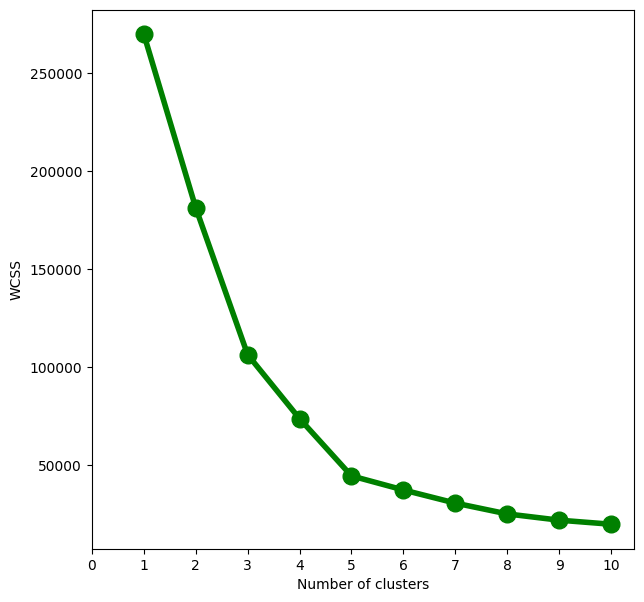

In [8]:
# find the optimal number of clusters using elbow method

WCSS = []
for i in range(1,11):
    model = KMeans(n_clusters = i,init='k-means++')
    model.fit(x)
    WCSS.append(model.inertia_)
fig = plt.figure(figsize = (7,7))
plt.plot(range(1,11),WCSS, linewidth=4, markersize=12,marker='o',color = 'green')
plt.xticks(np.arange(11))
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.show()


In [9]:
# since elbow occured at 5, hence the optimal number of clusters for the mall data is 5 

model = KMeans(n_clusters = 5, init = "k-means++", max_iter = 300, n_init = 10, random_state = 0)
y_clusters = model.fit_predict(x)

In [10]:
y_clusters

array([3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4,
       3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 0,
       3, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 0, 1, 2, 1, 2, 1,
       0, 1, 2, 1, 2, 1, 2, 1, 2, 1, 0, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1], dtype=int32)

In [11]:
x

array([[ 15,  39],
       [ 15,  81],
       [ 16,   6],
       [ 16,  77],
       [ 17,  40],
       [ 17,  76],
       [ 18,   6],
       [ 18,  94],
       [ 19,   3],
       [ 19,  72],
       [ 19,  14],
       [ 19,  99],
       [ 20,  15],
       [ 20,  77],
       [ 20,  13],
       [ 20,  79],
       [ 21,  35],
       [ 21,  66],
       [ 23,  29],
       [ 23,  98],
       [ 24,  35],
       [ 24,  73],
       [ 25,   5],
       [ 25,  73],
       [ 28,  14],
       [ 28,  82],
       [ 28,  32],
       [ 28,  61],
       [ 29,  31],
       [ 29,  87],
       [ 30,   4],
       [ 30,  73],
       [ 33,   4],
       [ 33,  92],
       [ 33,  14],
       [ 33,  81],
       [ 34,  17],
       [ 34,  73],
       [ 37,  26],
       [ 37,  75],
       [ 38,  35],
       [ 38,  92],
       [ 39,  36],
       [ 39,  61],
       [ 39,  28],
       [ 39,  65],
       [ 40,  55],
       [ 40,  47],
       [ 40,  42],
       [ 40,  42],
       [ 42,  52],
       [ 42,  60],
       [ 43,

In [31]:
y_clusters == 1

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False,  True, False,  True,
       False,  True,

In [24]:
x[y_clusters == 1,0]

array([39, 31, 40, 38, 39, 31, 29, 32, 35, 32, 32, 28, 32, 34, 39, 38, 27,
       30, 30, 29, 31, 36, 33, 32, 28, 36, 30, 27, 35, 32, 29, 30, 28, 36,
       32, 38, 35, 32, 30])

In [32]:
model.cluster_centers_

array([[ 23.46153846,  59.26923077,  49.15384615],
       [ 46.16      ,  61.32      ,  46.36      ],
       [ 24.80952381,  25.61904762,  80.23809524],
       [ 32.86206897,  78.55172414,  82.17241379],
       [ 41.        , 109.7       ,  22.        ],
       [ 34.5625    ,  32.8125    ,  42.625     ],
       [ 49.        ,  25.5       ,  12.28571429],
       [ 32.2       , 109.7       ,  82.        ],
       [ 41.        ,  80.18181818,  12.68181818],
       [ 61.44444444,  51.18518519,  50.44444444]])

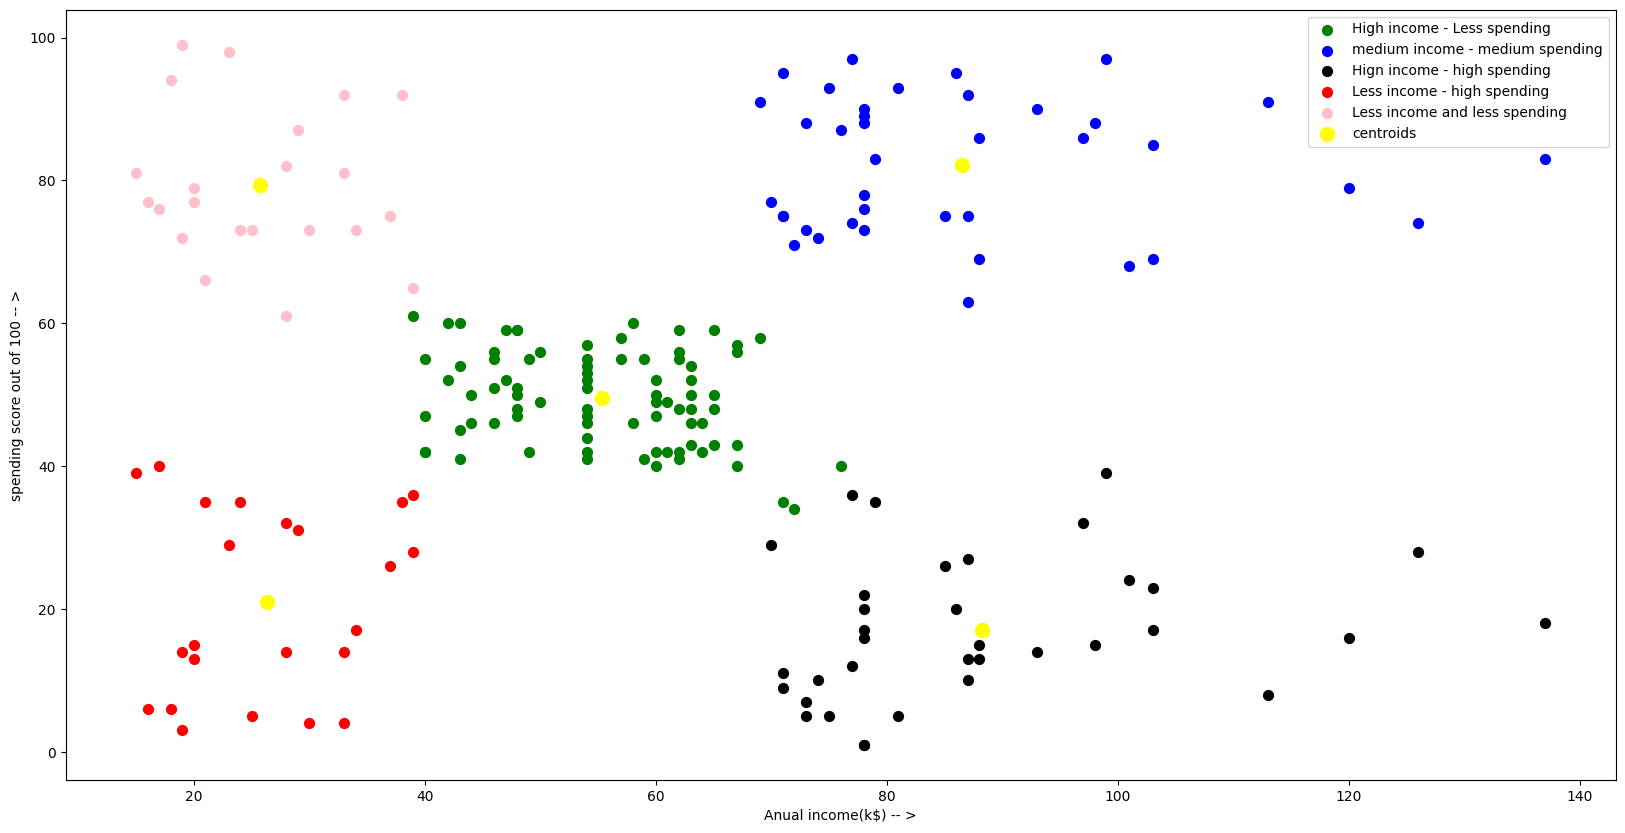

In [ ]:
plt.figure(figsize = (20,10))
#  x   -> annual income                        y -> spending score
plt.scatter(x[y_clusters == 0,0],x[y_clusters == 0,1],s = 50, c = 'green', label = "High income - Less spending") #first cluster 1st,2nd feature
plt.scatter(x[y_clusters == 1,0],x[y_clusters == 1,1],s = 50, c = 'blue', label = "medium income - medium spending")
plt.scatter(x[y_clusters == 2,0],x[y_clusters == 2,1],s = 50, c = 'black', label = "Hign income - high spending")
plt.scatter(x[y_clusters == 3,0],x[y_clusters == 3,1],s = 50, c = 'red', label = "Less income - high spending")
plt.scatter(x[y_clusters == 4,0],x[y_clusters == 4,1],s = 50, c = 'pink', label = "Less income and less spending")
plt.scatter(model.cluster_centers_[:,0],model.cluster_centers_[:,1], s = 100, c = "yellow", label = "centroids")
plt.xlabel("Anual income(k$) -- >")
plt.ylabel("spending score out of 100 -- >")
plt.legend()
plt.show()

**Now I'm going to include 3 independant variables such as age, anual income and the spending score in segmentation algorithm.**

In [13]:
# input matrix for segmentation
x = df[['Age','Annual Income (k$)','Spending Score (1-100)']].values

## Weighted Cluster Sum of Squares (WCSS) and elbow method

### What is WCSS?

**Weighted Cluster Sum of Squares (WCSS)** is a metric used to evaluate the compactness of clusters. It measures how close the data points in a cluster are to the cluster center (centroid or mean).

### WCSS Formula:

If we denote:

- $N$: Total number of data points  
- $K$: Number of clusters  
- $x_i$: A data point  
- $\mu_k$: The centroid of cluster $k$  
- $r_{ik}$: Responsibility or weight — the probability that point $x_i$ belongs to cluster $k$ (in soft clustering like GMM)

Then:

$$
\text{WCSS} = \sum_{i=1}^{N} \sum_{k=1}^{K} r_{ik} \| x_i - \mu_k \|^2
$$

---


So, **WCSS** generalizes to **weighted distances** when probabilities are involved.


### Why Is WCSS Important?

- A **lower WCSS** means that points are closer to their cluster centers → better clustering compactness.
- However, minimizing WCSS alone can lead to **overfitting** (e.g., assigning one point per cluster).




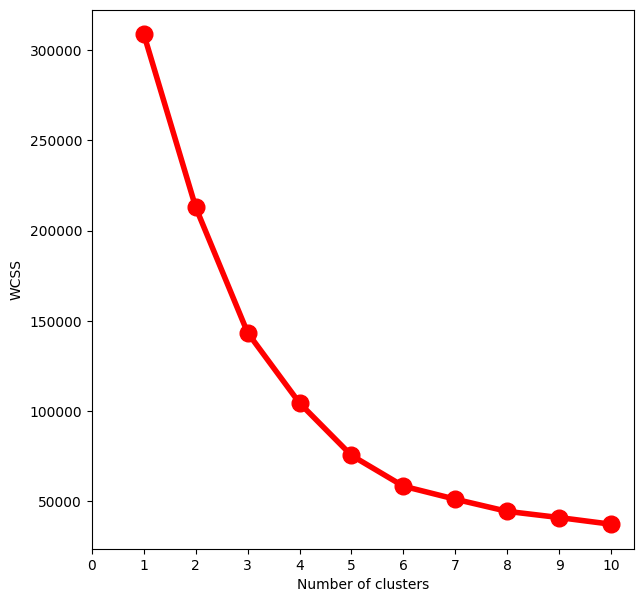

In [25]:
# find the optimal number of clusters using elbow method  -- >This is for 3 features = [age,anual income,spending score]

WCSS = []
for i in range(1,11):
    model = KMeans(n_clusters = i,init = 'k-means++')
    model.fit(x)
    WCSS.append(model.inertia_)
fig = plt.figure(figsize = (7,7))
plt.plot(range(1,11),WCSS, linewidth=4, markersize=12,marker='o',color = 'red')
plt.xticks(np.arange(11))
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.show()

From the above elbow method, we can see that the optimal number of clusters == 5


In [15]:
# finding the clusters based on input matrix "x"
model = KMeans(n_clusters = 5, init = "k-means++", max_iter = 300, n_init = 10, random_state = 0)
y_clusters = model.fit_predict(x)

<Axes: ylabel='count'>

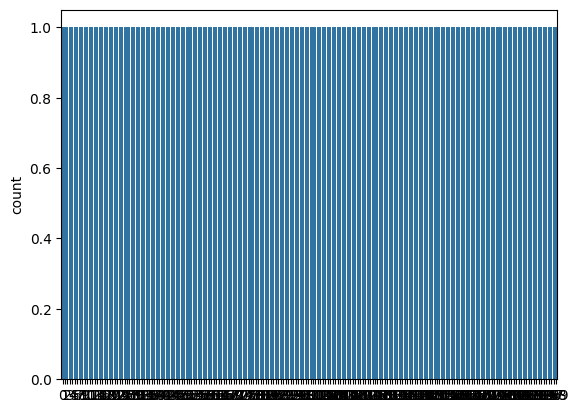

In [16]:
# countplot to check the number of clusters and number of customers in each cluster
sns.countplot(y_clusters)

From the above countplot we can see that there are more number of customers in the cluster 2(green color).
same colors are used to plot the clusters(In 3d scatter plot below).

In [17]:
print(x[y_clusters == 0,0][1])
print(x[y_clusters == 0,1][1])
print(x[y_clusters == 0,2][1])

20
16
6


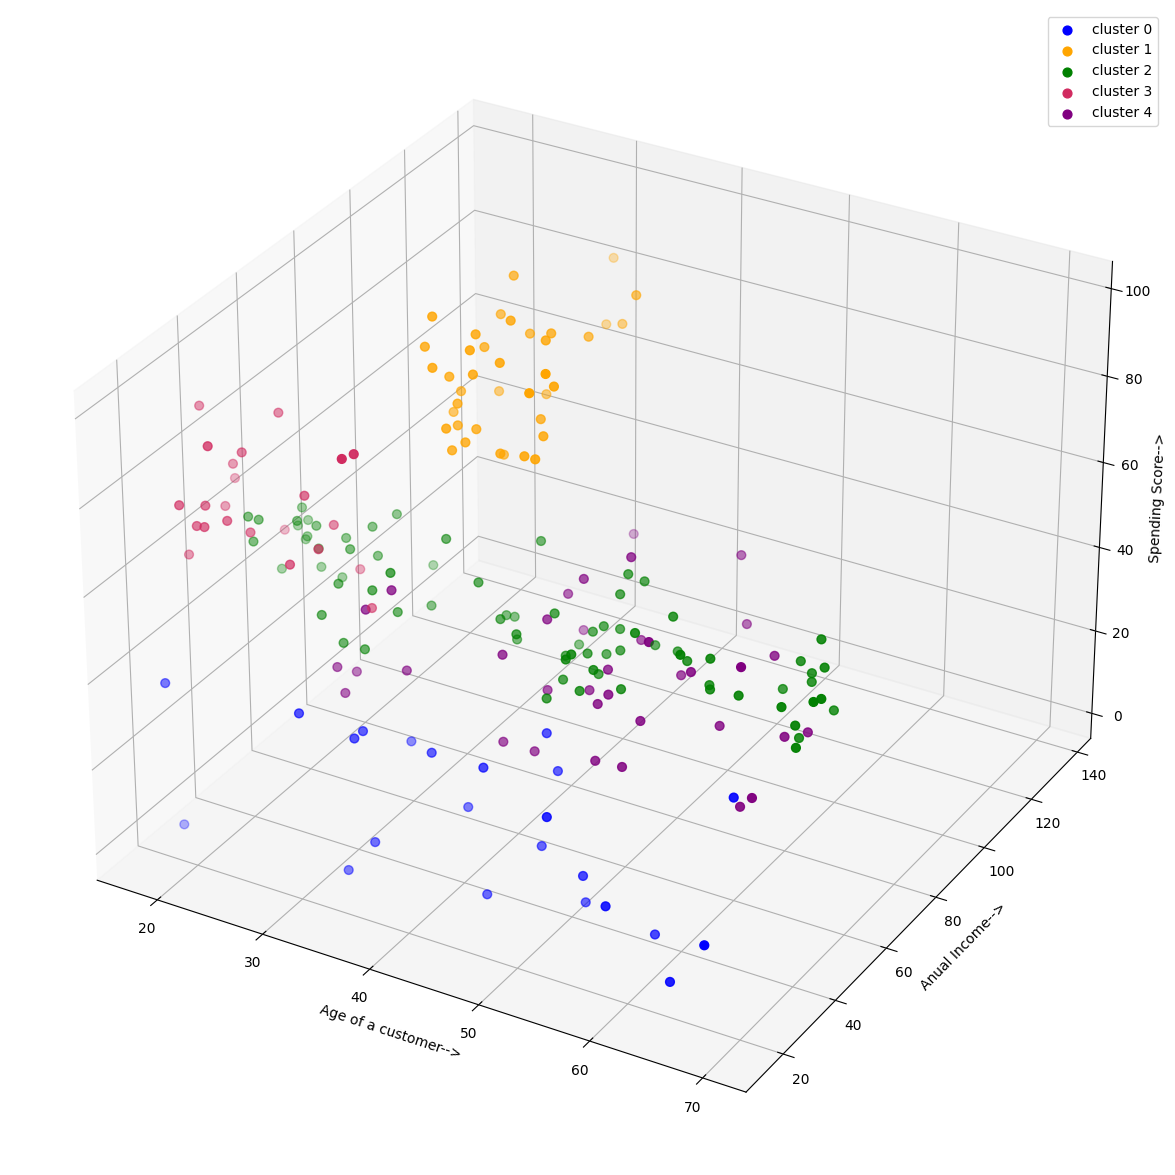

In [18]:
# 3d scatterplot using matplotlib

fig = plt.figure(figsize = (15,15))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(x[y_clusters == 0,0],x[y_clusters == 0,1],x[y_clusters == 0,2], s = 40 , color = 'blue', label = "cluster 0")
ax.scatter(x[y_clusters == 1,0],x[y_clusters == 1,1],x[y_clusters == 1,2], s = 40 , color = 'orange', label = "cluster 1")
ax.scatter(x[y_clusters == 2,0],x[y_clusters == 2,1],x[y_clusters == 2,2], s = 40 , color = 'green', label = "cluster 2")
ax.scatter(x[y_clusters == 3,0],x[y_clusters == 3,1],x[y_clusters == 3,2], s = 40 , color = '#D12B60', label = "cluster 3")
ax.scatter(x[y_clusters == 4,0],x[y_clusters == 4,1],x[y_clusters == 4,2], s = 40 , color = 'purple', label = "cluster 4")
ax.set_xlabel('Age of a customer-->')
ax.set_ylabel('Anual Income-->')
ax.set_zlabel('Spending Score-->')
ax.legend()
plt.show()


In [19]:
# 3d scatterplot using plotly
Scene = dict(xaxis = dict(title  = 'Age -->'),yaxis = dict(title  = 'Spending Score--->'),zaxis = dict(title  = 'Annual Income-->'))

# model.labels_ is nothing but the predicted clusters i.e y_clusters
labels = model.labels_
trace = go.Scatter3d(x=x[:, 0], y=x[:, 1], z=x[:, 2], mode='markers',marker=dict(color = labels, size= 10, line=dict(color= 'black',width = 10)))
layout = go.Layout(margin=dict(l=0,r=0),scene = Scene,height = 800,width = 800)
data = [trace]
fig = go.Figure(data = data, layout = layout)
fig.show()